# Pipeline control center

**SERS-D2DNet + SuperRaman · v0.2.0**

[Notebook guide](../docs/NOTEBOOK_GUIDE.md) · [Paper alignment](../docs/PAPER_IMPLEMENTATION_MAP.md) · [README](../README.md)

## Goal
Operate the full two-stage workflow from one notebook: select settings, prepare data, train the independent models, build a portable bundle, and compare predictions.

## Setup
Select the Python environment where `.[notebooks]` is installed. Edit `CONFIG` below to select the demo or your research configuration. Every notebook opens the same persistent run. Configuration changes require a new `run_directory`. The default executes a synthetic, one-epoch, width-2 demonstration across all four portable devices.

In [1]:
CONFIG = "configs/workflow_demo.json"
RUN_RESEARCH_TRAINING = False

In [2]:
import numpy as np
from sersd2d_superraman import __version__
from sersd2d_superraman.provenance import read_json
from sersd2d_superraman.data import load_batch
from sersd2d_superraman.notebook import (
    open_workflow,
    display_table,
    setup_plotting,
    training_plot,
    spectrum_plot,
    confusion_plot,
)

workflow = open_workflow(CONFIG)
PROJECT, settings = workflow.project, workflow.config
MODE = settings["mode"]
RUN_TRAINING = MODE == "demo" or RUN_RESEARCH_TRAINING
setup_plotting()
display_table(
    ["Control", "Value"],
    [
        ["Software", __version__],
        ["Mode", MODE],
        ["Devices", ", ".join(settings["sources"])],
        [
            "Translation width / epochs",
            f"{settings['translation_config']['model']['width']} / {settings['translation_config']['training']['epochs']}",
        ],
        ["Classifier epochs", settings["classifier_config"]["training"]["epochs"]],
        [
            "Classifier / translation device",
            f"{settings['classifier_device']} / {settings['translation_device']}",
        ],
        ["Research training requested", RUN_RESEARCH_TRAINING],
    ],
)

| Control | Value |
| --- | --- |
| Software | 0.2.0 |
| Mode | demo |
| Devices | Enwave, Tec5, Fdefender, RID |
| Translation width / epochs | 2 / 1 |
| Classifier epochs | 1 |
| Classifier / translation device | cpu / cpu |
| Research training requested | False |

### Read the execution scope
The demo verifies software behavior. Its plots and scores are synthetic and have no scientific performance interpretation. Research mode uses authorized preprocessed arrays and the recovered width-128 graph. Published-result reproduction remains unresolved; review the paper alignment document before reporting results.

## Steps
### 1. Prepare and audit the input roles
The interface accepts preprocessed `[N,1400]` spectra in `[0,1]`. Rows retain device, analyte, sample identity, optional Raman axis, and optional acquisition group. Class-matched training pairs are physically unpaired. Split checks keep duplicates and acquisition groups together.

In [3]:
counts = workflow.prepare()
display_table(
    ["Device", "Fit", "Validation", "Test"],
    [[d, r["train"], r["validation"], r["test"]] for d, r in counts.items()],
)

synthetic: verified existing artifacts


prepare: verified existing artifacts


| Device | Fit | Validation | Test |
| --- | --- | --- | --- |
| Renishaw | 60 | 20 | 20 |
| Enwave | 60 | 20 | 20 |
| Tec5 | 60 | 20 | 20 |
| Fdefender | 60 | 20 | 20 |
| RID | 60 | 20 | 20 |

### 2. Train one translator for each portable device
Every translator learns a source-to-Renishaw mapping independently. Deep supervision uses named heads; inference selects only the 1400-bin `out` head. The recovered graph is retained. A maximum of 50 class-matched fit pairs is requested in research mode; actual per-class counts are recorded, since small independent fit splits can contain fewer.

In [4]:
translation_runs = workflow.train_translations() if RUN_TRAINING else {}
if not RUN_TRAINING:
    print("Research translation training is disabled. Set RUN_RESEARCH_TRAINING = True in Setup to run it.")
display_table(
    ["Device", "Best epoch", "Validation MAE", "Fit pairs/class (min–max)"],
    [
        [
            d,
            r["best_epoch"],
            round(r["best_validation_out_mae"], 5),
            str(min(r["fit_class_counts"].values())) + "–" + str(max(r["fit_class_counts"].values())),
        ]
        for d, r in translation_runs.items()
    ],
)

synthetic: verified existing artifacts


prepare: verified existing artifacts


translation:Enwave: verified existing artifacts


translation:Tec5: verified existing artifacts


translation:Fdefender: verified existing artifacts


translation:RID: verified existing artifacts


| Device | Best epoch | Validation MAE | Fit pairs/class (min–max) |
| --- | --- | --- | --- |
| Enwave | 1 | 0.15752 | 1–1 |
| Tec5 | 1 | 0.15728 | 1–1 |
| Fdefender | 1 | 0.15733 | 1–1 |
| RID | 1 | 0.15733 | 1–1 |

### 3. Train the reusable Renishaw classifier
SuperRaman learns from the Renishaw fit role and selects checkpoints on independent Renishaw validation. The maintained implementation uses cross-entropy on logits and legacy fractional shifts. These differ from the paper's MAE/integer-shift wording and are identified in every configuration and the alignment map.

In [5]:
classifier_run = workflow.train_classifier() if RUN_TRAINING else None
if not RUN_TRAINING:
    print("Research classifier training is disabled. Set RUN_RESEARCH_TRAINING = True in Setup to run it.")
if classifier_run:
    print(
        {key: classifier_run[key] for key in ("best_epoch", "best_validation_loss", "objective", "synthetic")}
    )

synthetic: verified existing artifacts


prepare: verified existing artifacts


classifier: verified existing artifacts
{'best_epoch': 1, 'best_validation_loss': 2.9738950729370117, 'objective': 'cross_entropy_on_logits', 'synthetic': True}


### 4. Connect the models and evaluate the held-out cascade
A bundle copies one classifier and the selected translators. In separate workers, the same test rows follow two paths: original → classifier, and source → translator `out` → per-row `[-1,1]` classifier transform → classifier. Class-mean spectral agreement uses independent Renishaw test spectra.

In [6]:
ready = (workflow.output / "classification/checkpoint/metadata.json").is_file() and all(
    (workflow.output / "translation" / d / "checkpoint/metadata.json").is_file() for d in settings["sources"]
)
reports = {}
if ready:
    workflow.build_bundle()
    reports = workflow.evaluate()
    display_table(
        ["Device", "Original accuracy", "Translated accuracy", "MAE before", "MAE after"],
        [
            [
                d,
                round(r["classification"]["original"]["accuracy"], 4),
                round(r["classification"]["translated"]["accuracy"], 4),
                round(r["translation"]["before"]["mae"], 5),
                round(r["translation"]["after"]["mae"], 5),
            ]
            for d, r in reports.items()
        ],
    )
else:
    print("Evaluation pending: complete both training stages before building the bundle.")

bundle: verified existing artifacts


synthetic: verified existing artifacts


prepare: verified existing artifacts


predict:Enwave: verified existing artifacts
metrics:Enwave: verified existing artifacts


predict:Tec5: verified existing artifacts
metrics:Tec5: verified existing artifacts


predict:Fdefender: verified existing artifacts
metrics:Fdefender: verified existing artifacts


predict:RID: verified existing artifacts
metrics:RID: verified existing artifacts


| Device | Original accuracy | Translated accuracy | MAE before | MAE after |
| --- | --- | --- | --- | --- |
| Enwave | 0.05 | 0.05 | 0.01115 | 0.15732 |
| Tec5 | 0.05 | 0.05 | 0.01164 | 0.15708 |
| Fdefender | 0.05 | 0.05 | 0.01225 | 0.15713 |
| RID | 0.05 | 0.05 | 0.01305 | 0.15713 |

### 5. Inspect a class and the classification comparison
Change `DEVICE` and `CLASS_ID` to inspect the same held-out cohort. Shading shows between-spectrum standard deviation, not a confidence interval. A physical Raman axis is shown only when supplied; otherwise the axis is bin index.

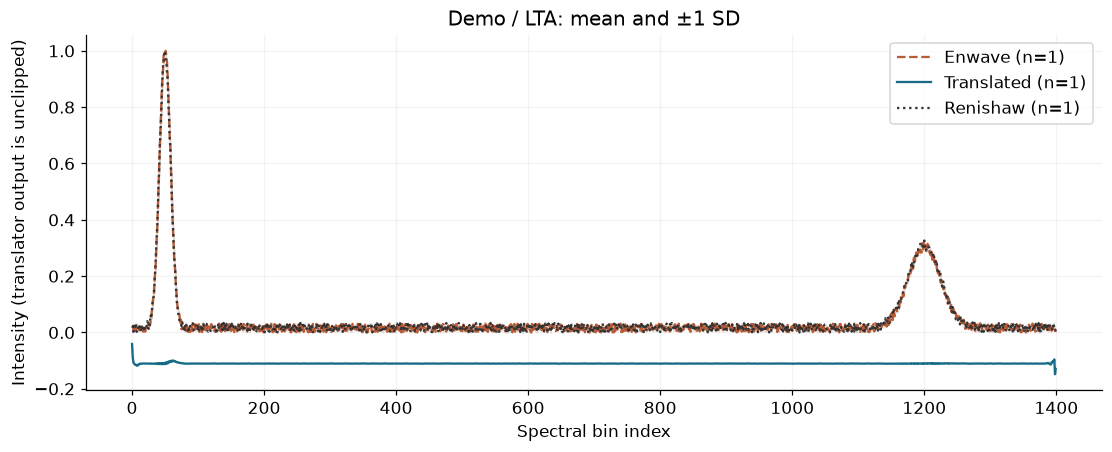

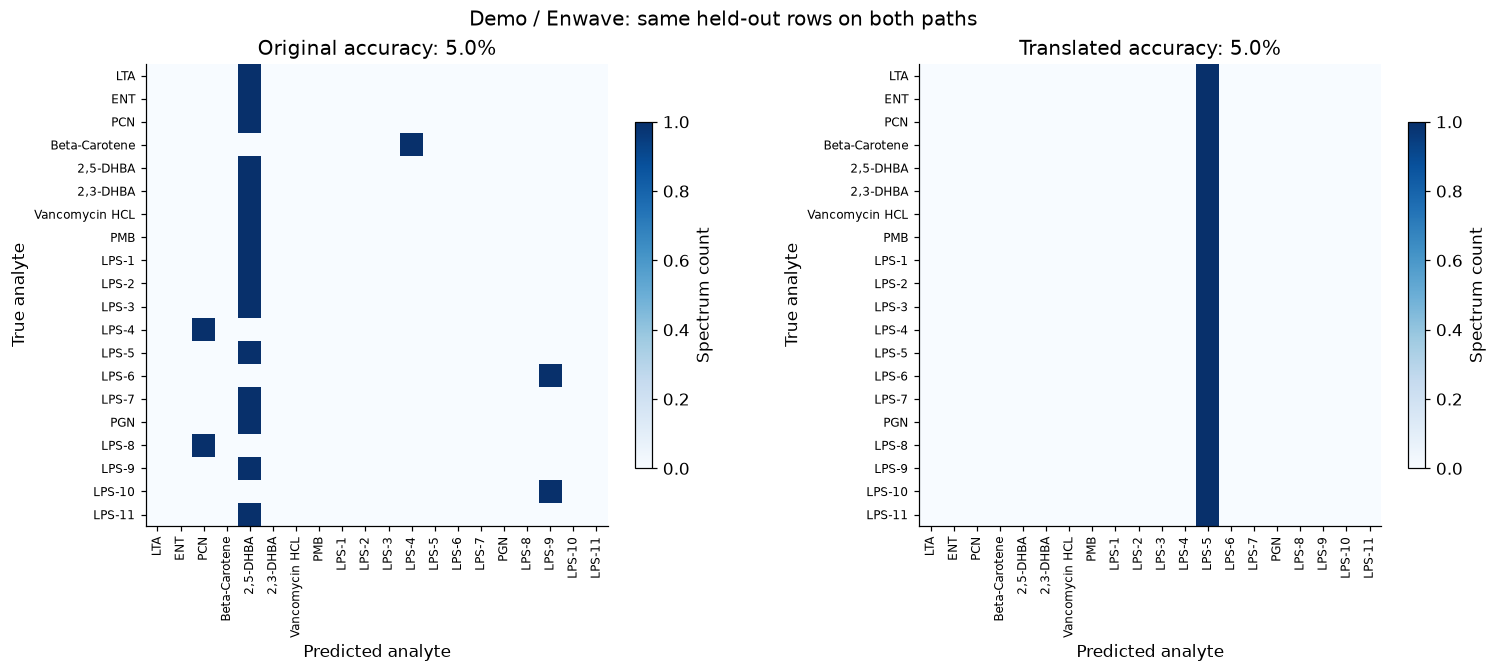

In [7]:
DEVICE = settings["sources"][0]
CLASS_ID = 0
if reports:
    spectrum_plot(workflow, DEVICE, CLASS_ID)
    import matplotlib.pyplot as plt

    plt.show()
    confusion_plot(workflow, DEVICE)
    plt.show()

### 6. Review validation histories
Each curve shows the criterion used for its model. A one-epoch demo is an execution check, not evidence of convergence.

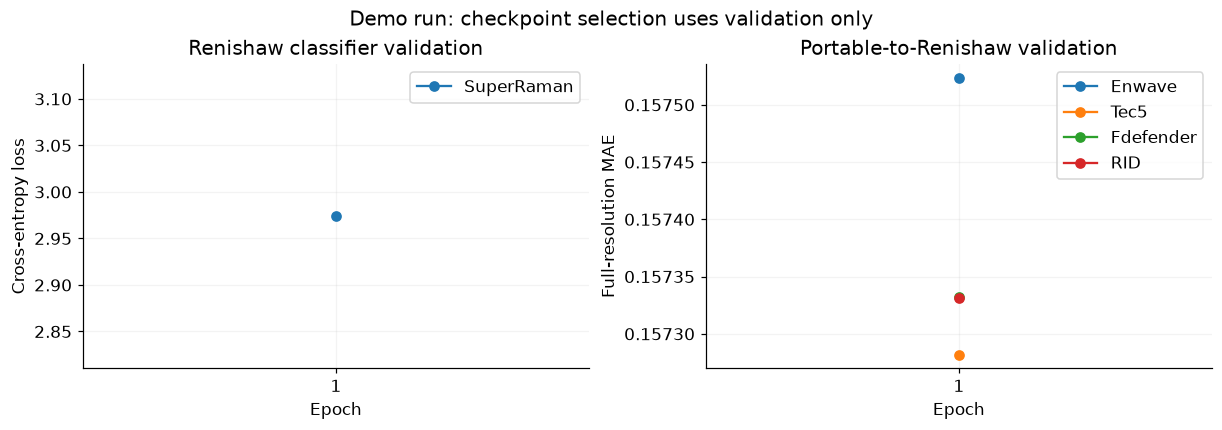

In [8]:
if ready:
    training_plot(workflow)
    plt.show()

### Paper alignment
The flow follows Sections 3.1 and 3.6: separate source-to-Renishaw translators and one reusable Renishaw classifier, compared before and after translation. Exact model/training/result parity is not established. The recovered translator is 61,511,562 parameters versus the paper's 6.15 M; pooling/interpolation and classifier shifts/loss also differ. Independent test isolation is a maintained protocol change.

## Checks
Artifact reuse checks file hashes and input/configuration identities. Test rows are evaluated after checkpoint selection; they do not choose the models.

In [9]:
display_table(["Stage", "Status"], workflow.status().items())

| Stage | Status |
| --- | --- |
| bundle | completed |
| classifier | completed |
| metrics:Enwave | completed |
| metrics:Fdefender | completed |
| metrics:RID | completed |
| metrics:Tec5 | completed |
| predict:Enwave | completed |
| predict:Fdefender | completed |
| predict:RID | completed |
| predict:Tec5 | completed |
| prepare | completed |
| synthetic | completed |
| translation:Enwave | completed |
| translation:Fdefender | completed |
| translation:RID | completed |
| translation:Tec5 | completed |

## Next Steps
For real experiments, copy `configs/workflow_research.json` to `configs/local/my_run.json`, set the data path and a new run directory, and select it in `CONFIG`. Set RUN_RESEARCH_TRAINING = True explicitly after reviewing the displayed settings. See the [notebook guide](../docs/NOTEBOOK_GUIDE.md) for stage navigation and interpretation.